# 01 — What a PDF page contains

## Objective

Compare a born-digital slide with a scanned letter and connect the visible page to the objects PyMuPDF can inspect: text, raster images, and vector drawings.

## Concept

A PDF page is a drawing program, not a semantic document. Text may be stored as positioned glyphs, figures may be pixels or vector paths, and a scan may be one page-sized image. Two pages that look similar can therefore require different extraction methods.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf

plt.style.use("seaborn-v0_8-whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
SLIDES_PDF = PROJECT_ROOT / "data" / "documents" / "ch2.pdf"
SCANNED_PDF = PROJECT_ROOT / "data" / "documents" / "scanned.pdf"

## Implementation — inspect one page of each type

The counts below are observable properties, not classifications. In particular, a scanned page can still contain a small native text overlay.

In [2]:
page_specs = [
    {"label": "born-digital slide", "path": SLIDES_PDF, "page_number": 9},
    {"label": "scanned letter", "path": SCANNED_PDF, "page_number": 1},
]

observations = []
for spec in page_specs:
    with pymupdf.open(spec["path"]) as document:
        page = document[spec["page_number"] - 1]
        observations.append(
            {
                "page": spec["label"],
                "native_words": len(page.get_text("words")),
                "raster_images": len(page.get_image_info()),
                "vector_drawings": len(page.get_drawings()),
                "native_preview": page.get_text("text")[:80].replace("\n", " ").strip(),
            }
        )

representation_table = pd.DataFrame(observations)
representation_table

,page,native_words,raster_images,vector_drawings,native_preview
0,born-digital slide,148,0,3,Why the support of the prior matters. II • In ...
1,scanned letter,2,1,0,SAMPLE LETTER


## Execution — render the pages

Rendering converts the drawing instructions into pixels. It shows what a person sees, independently of whether text extraction can recover the content.

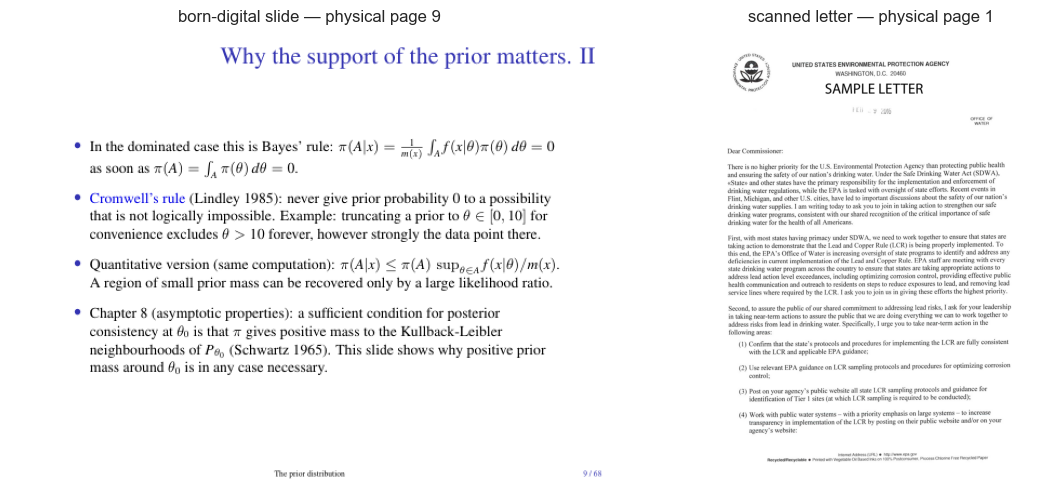

In [3]:
def pixmap_to_array(pixmap):
    rows = np.frombuffer(pixmap.samples, dtype=np.uint8)
    rows = rows.reshape(pixmap.height, pixmap.stride)[:, : pixmap.width * pixmap.n]
    return rows.reshape(pixmap.height, pixmap.width, pixmap.n)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, spec in zip(axes, page_specs):
    with pymupdf.open(spec["path"]) as document:
        page = document[spec["page_number"] - 1]
        pixmap = page.get_pixmap(dpi=110, alpha=False)
    ax.imshow(pixmap_to_array(pixmap))
    ax.set_title(f"{spec['label']} — physical page {spec['page_number']}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Inspection and interpretation

The scanned letter visibly contains a full body of text, but native extraction recovers only a small overlay. This is a concrete counterexample to the rule “any native text means the page is born-digital.” The slide exposes many native words, but later notebooks will show that equations, tables, and raster figures can still be misread.

## Validation

In [4]:
slide_row = representation_table.loc[representation_table["page"] == "born-digital slide"].iloc[0]
scan_row = representation_table.loc[representation_table["page"] == "scanned letter"].iloc[0]

assert slide_row["native_words"] > scan_row["native_words"]
assert scan_row["raster_images"] >= 1
assert scan_row["native_words"] > 0, "The intended edge case has disappeared"

print("Validated the mixed-content scan edge case.")

Validated the mixed-content scan edge case.


## Next step

`02_page_inspection.ipynb` turns these observations into explicit per-page features and checks them across representative pages. For a deeper anatomy study, keep `../experiments/pdf_anatomy.ipynb` as supporting reference material.